In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA

Data shape: (1797, 64)
Classes   : [0 1 2 3 4 5 6 7 8 9]


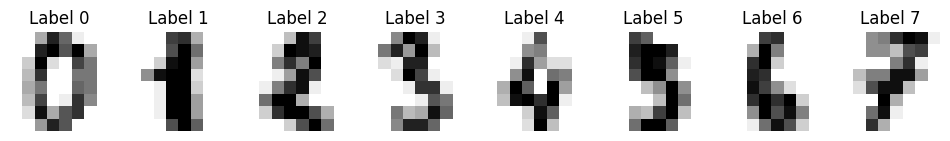

In [2]:
digits = load_digits()
X, y = digits.data, digits.target       # X = 64 pixel values per image, y = digit 0-9

print("Data shape:", X.shape)           # (1797, 64)
print("Classes   :", np.unique(y))

# Show a few sample images
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for i, ax in enumerate(axes):
    ax.imshow(X[i].reshape(8, 8), cmap="gray_r")
    ax.set_title(f"Label {y[i]}")
    ax.axis("off")
plt.show()

In [3]:
# Step 1: center the data (subtract the mean of each feature)
mean = X.mean(axis=0)
X_centered = X - mean

# Step 2: covariance matrix (64 x 64)
cov_matrix = np.cov(X_centered, rowvar=False)

# Step 3: eigenvalues and eigenvectors
eig_vals, eig_vecs = np.linalg.eigh(cov_matrix)

# Step 4: sort from largest to smallest eigenvalue
order = np.argsort(eig_vals)[::-1]
eig_vals = np.maximum(eig_vals[order], 0)    # remove tiny negative rounding errors
eig_vecs = eig_vecs[:, order]                # columns = principal components

# Step 5: explained variance ratio
explained_ratio = eig_vals / eig_vals.sum()

print("Covariance matrix shape:", cov_matrix.shape)
print("First 5 explained variance ratios:", np.round(explained_ratio[:5], 4))

Covariance matrix shape: (64, 64)
First 5 explained variance ratios: [0.1489 0.1362 0.1179 0.0841 0.0578]


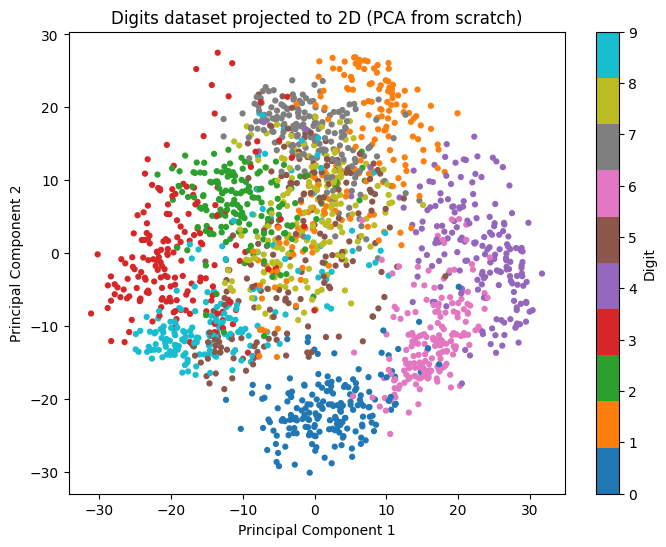

Variance explained by PC1 + PC2: 28.51 %


In [4]:
# Take the first 2 eigenvectors and project the data onto them
W2 = eig_vecs[:, :2]                  # shape (64, 2)
X_pca2 = X_centered @ W2              # shape (1797, 2)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca2[:, 0], X_pca2[:, 1], c=y, cmap="tab10", s=12)
plt.colorbar(scatter, label="Digit")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Digits dataset projected to 2D (PCA from scratch)")
plt.show()

print("Variance explained by PC1 + PC2:", round(explained_ratio[:2].sum() * 100, 2), "%")

k =  1 components -> reconstruction error (MSE) = 15.9777
k =  2 components -> reconstruction error (MSE) = 13.4210
k =  5 components -> reconstruction error (MSE) = 8.5424
k = 10 components -> reconstruction error (MSE) = 4.9143
k = 20 components -> reconstruction error (MSE) = 1.9843
k = 30 components -> reconstruction error (MSE) = 0.7681
k = 40 components -> reconstruction error (MSE) = 0.2215
k = 50 components -> reconstruction error (MSE) = 0.0085
k = 64 components -> reconstruction error (MSE) = 0.0000


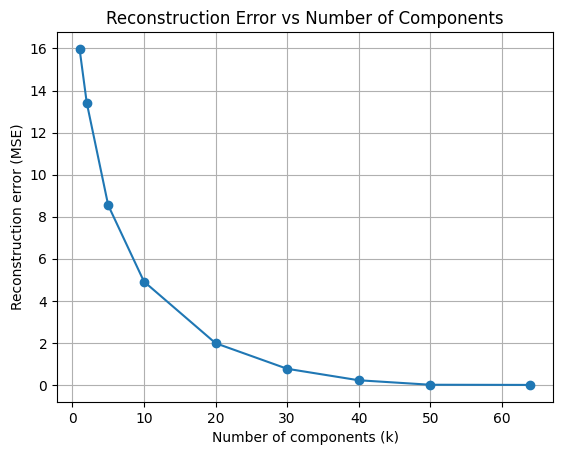

In [5]:
def reconstruct(k):
    """Compress to k components, then rebuild the original 64 pixels."""
    Wk = eig_vecs[:, :k]                 # first k principal components
    Z = X_centered @ Wk                  # compress (1797 x k)
    X_rec = Z @ Wk.T + mean              # decompress and add the mean back
    return X_rec

ks = [1, 2, 5, 10, 20, 30, 40, 50, 64]
errors = []
for k in ks:
    X_rec = reconstruct(k)
    mse = np.mean((X - X_rec) ** 2)      # average squared difference per pixel
    errors.append(mse)
    print(f"k = {k:2d} components -> reconstruction error (MSE) = {mse:.4f}")

plt.plot(ks, errors, marker="o")
plt.xlabel("Number of components (k)")
plt.ylabel("Reconstruction error (MSE)")
plt.title("Reconstruction Error vs Number of Components")
plt.grid(True)
plt.show()

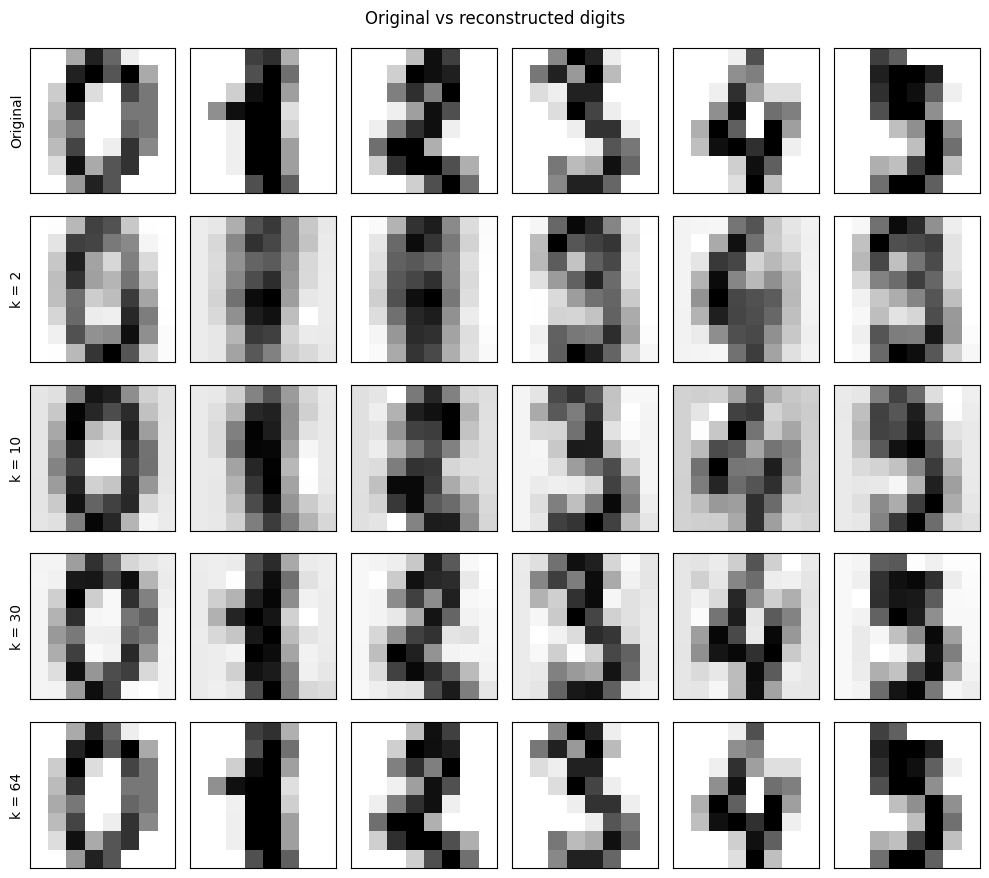

In [6]:
ks_show = [2, 10, 30, 64]
n_show = 6

fig, axes = plt.subplots(len(ks_show) + 1, n_show, figsize=(10, 9))

# Row 0: original images
for j in range(n_show):
    axes[0, j].imshow(X[j].reshape(8, 8), cmap="gray_r")
    axes[0, j].set_xticks([]); axes[0, j].set_yticks([])
axes[0, 0].set_ylabel("Original")

# Other rows: reconstructions with different k
for i, k in enumerate(ks_show):
    X_rec = reconstruct(k)
    for j in range(n_show):
        axes[i + 1, j].imshow(X_rec[j].reshape(8, 8), cmap="gray_r")
        axes[i + 1, j].set_xticks([]); axes[i + 1, j].set_yticks([])
    axes[i + 1, 0].set_ylabel(f"k = {k}")

plt.suptitle("Original vs reconstructed digits")
plt.tight_layout()
plt.show()

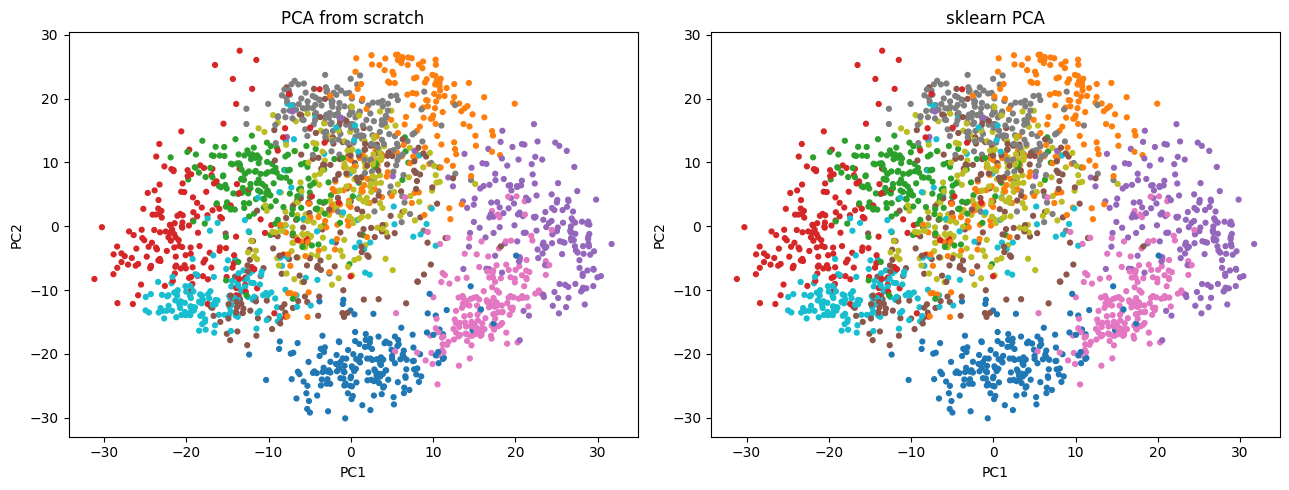

Explained variance ratio matches : True
2D projection matches (ignoring sign): True
Reconstruction error (k=10) -> ours   : 4.9143
Reconstruction error (k=10) -> sklearn: 4.9143


In [7]:
# sklearn PCA with all components
pca_full = PCA(n_components=64)
pca_full.fit(X)

# sklearn PCA with 2 components
pca2 = PCA(n_components=2)
X_sk2 = pca2.fit_transform(X)

# Side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(X_pca2[:, 0], X_pca2[:, 1], c=y, cmap="tab10", s=12)
axes[0].set_title("PCA from scratch")
axes[1].scatter(X_sk2[:, 0], X_sk2[:, 1], c=y, cmap="tab10", s=12)
axes[1].set_title("sklearn PCA")
for ax in axes:
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
plt.tight_layout()
plt.show()

# Numeric comparison
print("Explained variance ratio matches :", np.allclose(explained_ratio, pca_full.explained_variance_ratio_))
print("2D projection matches (ignoring sign):", np.allclose(np.abs(X_pca2), np.abs(X_sk2), atol=1e-6))

# Reconstruction error comparison for k = 10
k = 10
pca_k = PCA(n_components=k).fit(X)
X_rec_sk = pca_k.inverse_transform(pca_k.transform(X))
print("Reconstruction error (k=10) -> ours   :", round(np.mean((X - reconstruct(k)) ** 2), 4))
print("Reconstruction error (k=10) -> sklearn:", round(np.mean((X - X_rec_sk) ** 2), 4))

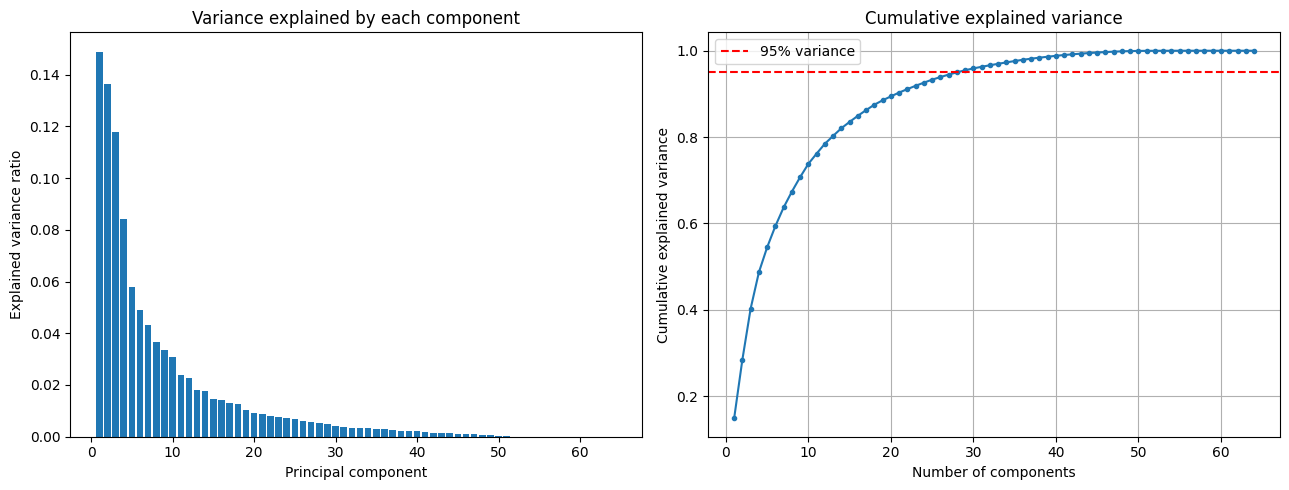

Components needed for 95% of the variance: 29 out of 64


In [8]:
cumulative = np.cumsum(pca_full.explained_variance_ratio_)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: variance of each individual component
axes[0].bar(range(1, 65), pca_full.explained_variance_ratio_)
axes[0].set_xlabel("Principal component")
axes[0].set_ylabel("Explained variance ratio")
axes[0].set_title("Variance explained by each component")

# Right: cumulative variance
axes[1].plot(range(1, 65), cumulative, marker="o", markersize=3)
axes[1].axhline(0.95, color="red", linestyle="--", label="95% variance")
axes[1].set_xlabel("Number of components")
axes[1].set_ylabel("Cumulative explained variance")
axes[1].set_title("Cumulative explained variance")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

n_95 = np.argmax(cumulative >= 0.95) + 1
print("Components needed for 95% of the variance:", n_95, "out of 64")